**Lab02 — Web Scraping, Feature Engineering and Exploratory Data Analysis**

Instructor Name: Attique-ur-Rehman

Student Name: Fatima Kashif

Sap Id: 70177832

**Data source: Sapphire Pakistan**

In [ ]:
# Installation of required libraries (run once per Colab session)
!pip install requests beautifulsoup4 lxml pandas spacy matplotlib seaborn textblob

# Download the small English language model for spaCy
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 25.8 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import numpy as np
import time

size = 10_000_000
data = np.random.rand(size)

# --- NumPy vectorised sum ---
start_np = time.time()
np_sum = np.sum(data)
end_np = time.time()

# --- Manual Python loop ---
start_py = time.time()
manual_sum = 0
for val in data:
    manual_sum += val
end_py = time.time()

print(f"NumPy Sum : {np_sum:.2f} | Time: {end_np - start_np:.5f} sec")
print(f"Manual Sum: {manual_sum:.2f} | Time: {end_py - start_py:.5f} sec")
print()
print(f"NumPy is {(end_py - start_py) / (end_np - start_np):.0f}x faster on this machine.")

NumPy Sum : 5001028.93 | Time: 0.00801 sec
Manual Sum: 5001028.93 | Time: 2.30640 sec

NumPy is 288x faster on this machine.


In [ ]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin
import pandas as pd
import time
import re
import json

headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}

# Open a Sapphire category page in your browser (e.g. Unstitched / 3 Piece) and paste its URL here
COLLECTION_URL = "https://pk.sapphireonline.pk/collections/uns-three-piece"
MAX_PRODUCTS = 10

res = requests.get(COLLECTION_URL, headers=headers, timeout=15)
print("Status code:", res.status_code)
soup = BeautifulSoup(res.content, "lxml")

links = []
for a in soup.find_all("a", href=True):
    if "/products/" in a["href"]:
        full = urljoin(COLLECTION_URL, a["href"].split("?")[0])
        if full not in links:
            links.append(full)

urls = links[:MAX_PRODUCTS]
print(f"Found {len(links)} product links, using {len(urls)}:")
for u in urls:
    print(" ", u)

Status code: 200
Found 12 product links, using 10:
  https://pk.sapphireonline.pk/collections/unstitched/products/U3PEST26V948.html
  https://pk.sapphireonline.pk/collections/unstitched/products/U3PEST26V945.html
  https://pk.sapphireonline.pk/collections/unstitched/products/U3PEST26V930.html
  https://pk.sapphireonline.pk/collections/unstitched/products/U3PELXS26V96.html
  https://pk.sapphireonline.pk/collections/unstitched/products/3PESGS26V105.html
  https://pk.sapphireonline.pk/collections/unstitched/products/TEDYS26V1013.html
  https://pk.sapphireonline.pk/collections/unstitched/products/PESTS26V1044.html
  https://pk.sapphireonline.pk/collections/unstitched/products/PESTS26V1046.html
  https://pk.sapphireonline.pk/collections/unstitched/products/PESTS26V1043.html
  https://pk.sapphireonline.pk/collections/unstitched/products/2TEDYS26V108.html


In [ ]:
# Diagnostic: look at the first product page to see what is really in the HTML
test = requests.get(urls[0], headers=headers, timeout=15)
s = BeautifulSoup(test.content, "lxml")

print("Title tag      :", s.title.get_text(strip=True) if s.title else None)
print("First <h1>     :", s.find("h1").get_text(strip=True) if s.find("h1") else None)
print("meta description:", (s.find("meta", attrs={"name": "description"}) or {}).get("content"))
print("JSON-LD blocks :", len(s.find_all("script", type="application/ld+json")))
print("<p> tags       :", len(s.find_all("p")))
print("Classes containing 'description':",
      sorted({c for t in s.find_all(class_=re.compile("descri", re.I)) for c in t.get("class", [])})[:15])

Title tag      : Unstitched 3 PC U3PEST26V948 Sapphire PK
First <h1>     : Unstitched 3 PC U3PEST26V948 Sapphire PK
meta description: Shop SAPPHIRE online for ladies three-piece embroidered multi ensemble U3PEST26V948 from Unstitched Winter new arrivals
JSON-LD blocks : 3
<p> tags       : 32
Classes containing 'description': ['description-and-detail']


In [ ]:
def get_title(soup):
    # Product name is normally in the page's first <h1>
    h = soup.find("h1")
    if h and h.get_text(strip=True):
        return h.get_text(strip=True)
    return soup.title.get_text(strip=True)

def get_description(soup):
    # Collect every place a product description may live, keep the longest one
    candidates = []

    # 1. Structured data (JSON-LD) used by most e-commerce sites
    for tag in soup.find_all("script", type="application/ld+json"):
        try:
            blob = json.loads(tag.string)
        except Exception:
            continue
        for item in (blob if isinstance(blob, list) else [blob]):
            if isinstance(item, dict) and item.get("description"):
                candidates.append(item["description"])

    # 2. Meta description tag
    meta = soup.find("meta", attrs={"name": "description"}) or soup.find("meta", property="og:description")
    if meta and meta.get("content"):
        candidates.append(meta["content"])

    # 3. Paragraphs inside the description block (same idea as the lab's content_div)
    block = soup.find(["div", "section"], class_=re.compile("descri|product-detail|pdp", re.I))
    if block:
        candidates.append(" ".join(p.get_text(strip=True) for p in block.find_all("p")))

    candidates = [BeautifulSoup(c, "lxml").get_text(" ", strip=True) for c in candidates if c]
    return max(candidates, key=len) if candidates else ""

articles = []

for url in urls:
    try:
        res = requests.get(url, headers=headers, timeout=10)
        res.raise_for_status()
        soup = BeautifulSoup(res.content, "lxml")

        title = get_title(soup)
        text = get_description(soup)

        # Product descriptions are shorter than blog posts, so the quality threshold is lower
        if len(text) > 50:
            articles.append({"url": url, "title": title, "text": text})
        else:
            print(f"[SKIP] Too short / no description found: {url}")

        time.sleep(1)   # Be polite to the server
    except Exception as e:
        print(f"[ERROR] {url} -> {e}")

df = pd.DataFrame(articles)
print(f"\nScraped {len(df)} of {len(urls)} products.")
df.head()


Scraped 10 of 10 products.


,url,title,text
0,https://pk.sapphireonline.pk/collections/unsti...,Unstitched 3 PC U3PEST26V948 Sapphire PK,NEW IN Pay in 3 Installments of Rs. Pay only ...
1,https://pk.sapphireonline.pk/collections/unsti...,Unstitched 3 PC U3PEST26V945 Sapphire PK,NEW IN Pay in 3 Installments of Rs. Pay only ...
2,https://pk.sapphireonline.pk/collections/unsti...,Unstitched 3 PC U3PEST26V930 Sapphire PK,NEW IN Pay in 3 Installments of Rs. Pay only ...
3,https://pk.sapphireonline.pk/collections/unsti...,Unstitched 3 PC U3PELXS26V96 Sapphire PK,NEW IN Pay in 3 Installments of Rs. Pay only ...
4,https://pk.sapphireonline.pk/collections/unsti...,Unstitched 3 PC 3PESGS26V105 Sapphire PK,NEW IN Pay in 3 Installments of Rs. Pay only ...


In [ ]:
# Save the raw scrape immediately so the rest of the lab works offline
if not df.empty:
    df.to_csv("articles_raw.csv", index=False)
    print("Saved articles_raw.csv")
else:
    df = pd.read_csv("articles_raw.csv")
    print("Network scrape empty -- loaded the cached articles_raw.csv instead.")

print(df.shape)

Saved articles_raw.csv
(10, 3)


In [ ]:
import spacy
import pandas as pd

nlp = spacy.load("en_core_web_sm")

def extract_features(text):
    """Process text with spaCy and extract four linguistic features."""
    doc = nlp(text)
    return pd.Series({
        'num_tokens':    len(doc),
        'num_sentences': len(list(doc.sents)),
        'num_entities':  len(doc.ents),
        'num_nouns':     len([t for t in doc if t.pos_ == 'NOUN'])
    })

if not df.empty:
    features = df['text'].apply(extract_features)
    df = pd.concat([df, features], axis=1)

    df['title_length'] = df['title'].apply(len)

    print("Features extracted successfully.")
    display(df[['title', 'num_tokens', 'num_sentences', 'num_entities', 'num_nouns']].head())
else:
    print("No articles found for feature extraction.")

Features extracted successfully.


,title,num_tokens,num_sentences,num_entities,num_nouns
0,Unstitched 3 PC U3PEST26V948 Sapphire PK,103,6,5,16
1,Unstitched 3 PC U3PEST26V945 Sapphire PK,101,7,6,17
2,Unstitched 3 PC U3PEST26V930 Sapphire PK,101,7,7,18
3,Unstitched 3 PC U3PELXS26V96 Sapphire PK,102,9,5,16
4,Unstitched 3 PC 3PESGS26V105 Sapphire PK,104,7,4,16


In [ ]:
# Inspect WHAT spaCy actually found
doc = nlp(df['text'].iloc[0][:1500])

print("Named entities in product 1:\n")
for ent in list(doc.ents)[:15]:
    print(f"  {ent.text:<35} {ent.label_:<12} ({spacy.explain(ent.label_)})")

Named entities in product 1:

  3                                   CARDINAL     (Numerals that do not fall under another type)
  3                                   CARDINAL     (Numerals that do not fall under another type)
  Khaddar Trouser                     PERSON       (People, including fictional)
  three                               CARDINAL     (Numerals that do not fall under another type)
  Share this Look                     WORK_OF_ART  (Titles of books, songs, etc.)


In [ ]:
from textblob import TextBlob

def get_sentiment(text):
    blob = TextBlob(text)
    return pd.Series({
        'sentiment_polarity':     blob.sentiment.polarity,
        'sentiment_subjectivity': blob.sentiment.subjectivity
    })

if not df.empty:
    sentiment_features = df['text'].apply(get_sentiment)
    df = pd.concat([df, sentiment_features], axis=1)

    print("Sentiment features extracted successfully.\n")
    display(df[['title', 'sentiment_polarity', 'sentiment_subjectivity']])

Sentiment features extracted successfully.



,title,sentiment_polarity,sentiment_subjectivity
0,Unstitched 3 PC U3PEST26V948 Sapphire PK,0.236136,0.507955
1,Unstitched 3 PC U3PEST26V945 Sapphire PK,0.262374,0.553283
2,Unstitched 3 PC U3PEST26V930 Sapphire PK,0.240152,0.575505
3,Unstitched 3 PC U3PELXS26V96 Sapphire PK,0.011509,0.577360
4,Unstitched 3 PC 3PESGS26V105 Sapphire PK,0.260227,0.563258
5,Unstitched 2 PC TEDYS26V1013 Sapphire PK,0.352273,0.635909
6,Unstitched 3 PC PESTS26V1044 Sapphire PK,0.352273,0.615909
7,Unstitched 3 PC PESTS26V1046 Sapphire PK,0.195707,0.386616
8,Unstitched 3 PC PESTS26V1043 Sapphire PK,0.265783,0.585480
9,Unstitched 2 PC 2TEDYS26V108 Sapphire PK,0.440341,0.769886


In [ ]:
# Persist the fully engineered table -- the Lab 02 deliverable
df.to_csv("articles.csv", index=False)
print("Saved articles.csv with", df.shape[1], "columns:")
print(list(df.columns))

Saved articles.csv with 10 columns:
['url', 'title', 'text', 'num_tokens', 'num_sentences', 'num_entities', 'num_nouns', 'title_length', 'sentiment_polarity', 'sentiment_subjectivity']


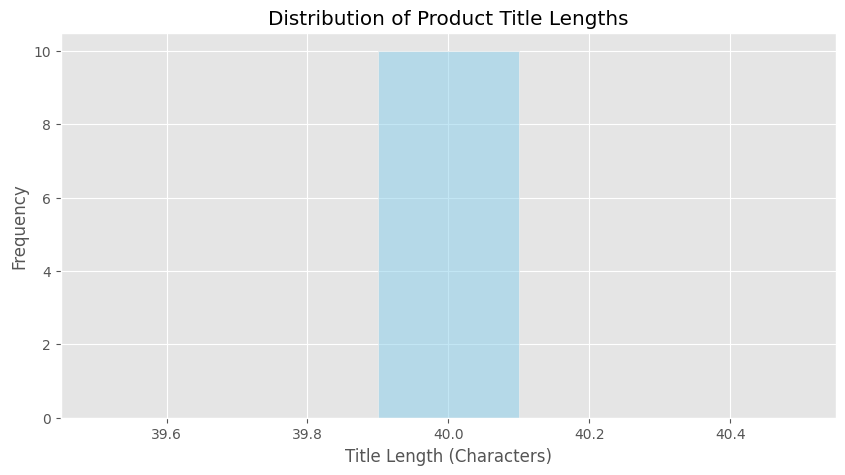

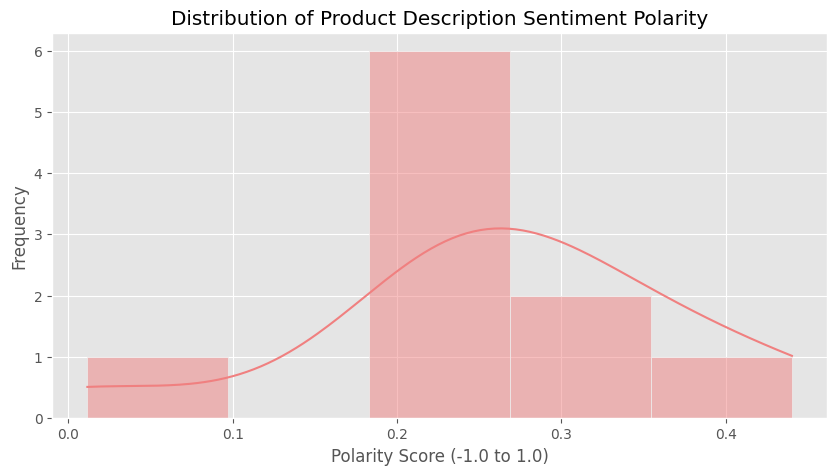

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

# 1. Title Length Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['title_length'], kde=True, bins=5, color='skyblue')
plt.title('Distribution of Product Title Lengths')
plt.xlabel('Title Length (Characters)')
plt.ylabel('Frequency')
plt.show()

# 2. Sentiment Polarity Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df['sentiment_polarity'], kde=True, bins=5, color='lightcoral')
plt.title('Distribution of Product Description Sentiment Polarity')
plt.xlabel('Polarity Score (-1.0 to 1.0)')
plt.ylabel('Frequency')
plt.show()

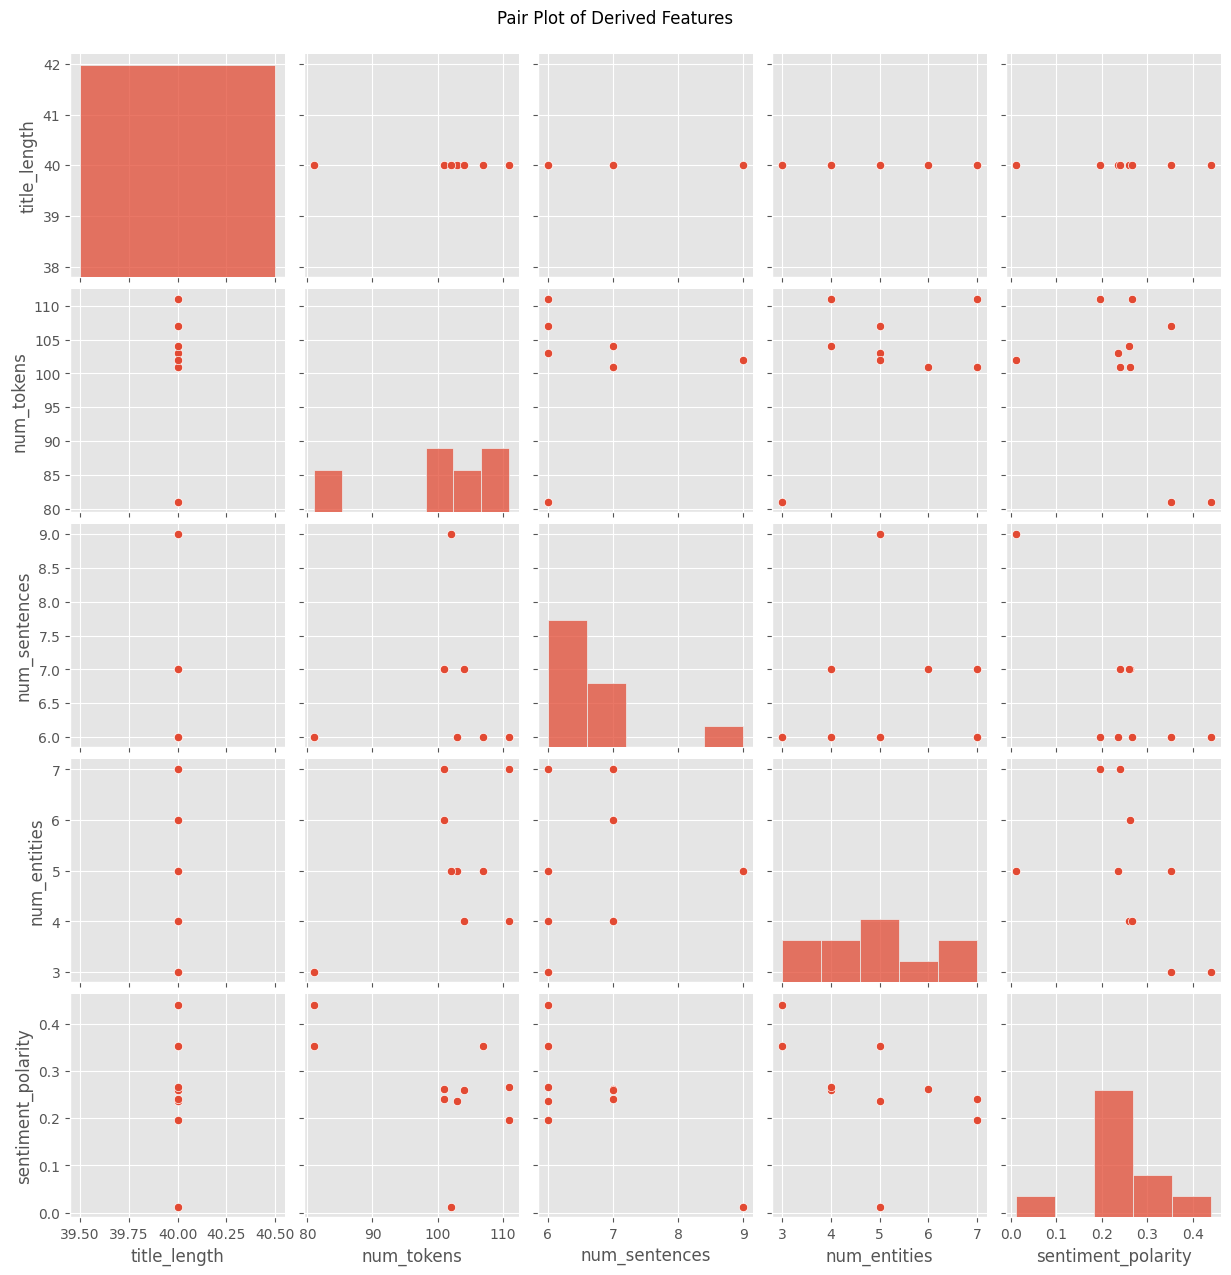

In [ ]:
numeric_cols = [
    'title_length',
    'num_tokens',
    'num_sentences',
    'num_entities',
    'sentiment_polarity'
]

sns.pairplot(df[numeric_cols])
plt.suptitle('Pair Plot of Derived Features', y=1.02)
plt.show()

In [ ]:
print("Correlation matrix:\n")
display(df[numeric_cols].corr().round(2))

Correlation matrix:



,title_length,num_tokens,num_sentences,num_entities,sentiment_polarity
title_length,NaN,NaN,NaN,NaN,NaN
num_tokens,NaN,1.00,0.12,0.61,-0.52
num_sentences,NaN,0.12,1.00,0.21,-0.78
num_entities,NaN,0.61,0.21,1.00,-0.48
sentiment_polarity,NaN,-0.52,-0.78,-0.48,1.00


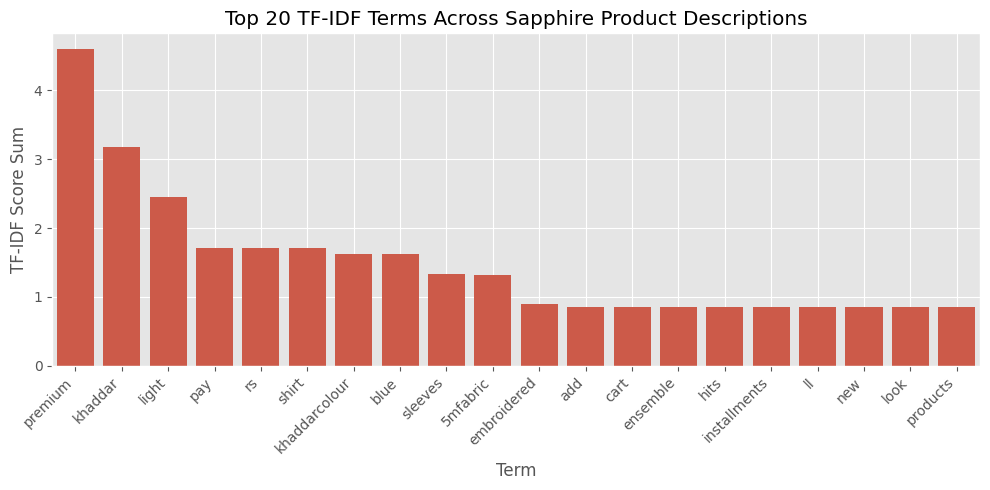

Sparse matrix shape (documents x terms): (10, 20)


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(stop_words='english', max_features=20)

X = vectorizer.fit_transform(df['text'])
tfidf_df = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())

tfidf_sums = tfidf_df.sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=tfidf_sums.index, y=tfidf_sums.values)
plt.title("Top 20 TF-IDF Terms Across Sapphire Product Descriptions")
plt.ylabel("TF-IDF Score Sum")
plt.xlabel("Term")
plt.xticks(rotation=45, ha='right')
plt.grid(True)
plt.tight_layout()
plt.show()

print("Sparse matrix shape (documents x terms):", X.shape)